![](https://miro.medium.com/v2/resize:fit:464/1*P9PzWUBv7RsNexqZWVXNcA.png)

This assignment focuses on building and analyzing a Bayesian Network (BN) to explore relationships between health and demographic factors. The task involves defining the BN structure based on expert knowledge, learning its parameters from a dataset, and visualizing the network. The variables include factors like age, gender, education, urbanization, and health outcomes such as asthma.

# Import the Dataset

In [1]:
import pandas as pd

# Load the Excel file
data = pd.read_excel("//kaggle/input/bayesian-network-dataset/data_bn.xlsx")

# Display the first few rows of the dataset
data.head()


,sex,age,urbanization,education,geographic_area,allergy,smoke,sedentary,asthma
0,male,adult,low,low,south/islands,yes,yes,yes,yes
1,female,old,low,low,south/islands,yes,no,yes,yes
2,female,adult,high,high,centre,no,no,yes,yes
3,male,adult,medium,low,south/islands,yes,no,no,no
4,female,adult,low,high,north,no,no,no,no


Checking if there's any missing values in our dataset

In [2]:
data.isnull().sum()

sex                0
age                0
urbanization       0
education          0
geographic_area    0
allergy            0
smoke              0
sedentary          0
asthma             0
dtype: int64

Checking the values of each column

In [3]:
for i in data.columns:
    print(i, "has", data[i].unique())
    print("---------------")


sex has ['male' 'female']
---------------
age has ['adult' 'old' 'young']
---------------
urbanization has ['low' 'high' 'medium']
---------------
education has ['low' 'high']
---------------
geographic_area has ['south/islands' 'centre' 'north']
---------------
allergy has ['yes' 'no']
---------------
smoke has ['yes' 'no']
---------------
sedentary has ['yes' 'no']
---------------
asthma has ['yes' 'no']
---------------


# Encoding

Since the values of each column are categorical. We have to encode those string values so they can be integers (0,1,...)

In [4]:
from sklearn.preprocessing import LabelEncoder

for i in data.columns:
    le = LabelEncoder()
    data[i]= le.fit_transform(data[i])
data.head()

,sex,age,urbanization,education,geographic_area,allergy,smoke,sedentary,asthma
0,1,0,1,1,2,1,1,1,1
1,0,1,1,1,2,1,0,1,1
2,0,0,0,0,0,0,0,1,1
3,1,0,2,1,2,1,0,0,0
4,0,0,1,0,1,0,0,0,0


In [1]:
pip install pyAgrum

   ---------------------------------------- 0.0/6.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/6.7 MB ? eta -:--:--
   ---- ----------------------------------- 0.8/6.7 MB 3.3 MB/s eta 0:00:02
   -------------- ------------------------- 2.4/6.7 MB 5.3 MB/s eta 0:00:01
   ------------------------ --------------- 4.2/6.7 MB 6.6 MB/s eta 0:00:01
   -------------------------------- ------- 5.5/6.7 MB 6.5 MB/s eta 0:00:01
   ---------------------------------------- 6.7/6.7 MB 6.4 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


# Bayesian Network Tree

Nodes in DAG: {'ALG', 'GEO', 'URB', 'SMK', 'SED', 'SEX', 'ASTHMA', 'AGE', 'EDU'}
Arcs in DAG: {(2, 7), (4, 3), (5, 8), (6, 8), (0, 3), (3, 2), (2, 5), (1, 3), (7, 8)}


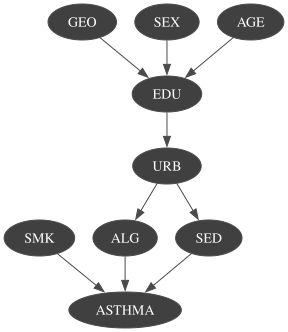

In [6]:
import pyAgrum as gum
import pyAgrum.lib.notebook as gnb

# Create an empty Bayesian Network
bn = gum.BayesNet("ExpertSystem")

# Add nodes (variables) with the number of states corresponding to your encoded data
bn.add(gum.LabelizedVariable("SEX", "Sex", 2))   # 2 states: male (0), female (1)
bn.add(gum.LabelizedVariable("AGE", "Age", 3))   # 3 states: young (0), adult (1), old (2)
bn.add(gum.LabelizedVariable("URB", "Urbanization", 3))  # 3 states: low (0), medium (1), high (2)
bn.add(gum.LabelizedVariable("EDU", "Education", 2))  # 2 states: low (0), high (1)
bn.add(gum.LabelizedVariable("GEO", "Geographic Area", 3))  # 3 states: north (0), centre (1), south/islands (2)
bn.add(gum.LabelizedVariable("ALG", "Allergy", 2))   # 2 states: no (0), yes (1)
bn.add(gum.LabelizedVariable("SMK", "Smoking", 2))   # 2 states: no (0), yes (1)
bn.add(gum.LabelizedVariable("SED", "Sedentary", 2))  # 2 states: no (0), yes (1)
bn.add(gum.LabelizedVariable("ASTHMA", "Asthma", 2))  # 2 states: no (0), yes (1)

# Add arcs based on the expert system structure
arcs = [
    ("SEX", "EDU"),
    ("AGE", "EDU"),
    ("GEO", "EDU"),
    ("EDU", "URB"),
    ("URB", "ALG"),
    ("URB", "SED"),
    ("SMK", "ASTHMA"),
    ("ALG", "ASTHMA"),
    ("SED", "ASTHMA")
]
for arc in arcs:
    bn.addArc(*arc)

# Display the network structure
print("Nodes in DAG:", bn.names())
print("Arcs in DAG:", bn.arcs())

# Graphical representation of the Bayesian Network
gnb.showBN(bn)


* AGE, SEX, and GEO are root nodes, meaning they are independent of other variables in this network.
* EDU (Education) depends on the demographic factors AGE, SEX, and GEO.
* URB (Urbanization) depends on EDU, showing a potential link between education and the level of urbanization.
* ALG (Allergy), SED (Sedentary), and SMK (Smoking) depend on URB, indicating that urbanization may influence these health and lifestyle factors.
* ASTHMA, the target variable, is influenced by ALG, SED, and SMK, reflecting its multifactorial nature.

In [7]:
column_mapping = {
    "sex": "SEX",
    "age": "AGE",
    "urbanization": "URB",
    "education": "EDU",
    "geographic_area": "GEO",
    "allergy": "ALG",
    "smoke": "SMK",
    "sedentary": "SED",
    "asthma": "ASTHMA"
}

# Rename the columns
data.rename(columns=column_mapping, inplace=True)

Give an abbreviation to the features name 

In [8]:
print(data.isnull().sum())  # Check for missing values


SEX       0
AGE       0
URB       0
EDU       0
GEO       0
ALG       0
SMK       0
SED       0
ASTHMA    0
dtype: int64


In [9]:
data["GEO"].unique()

array([2, 0, 1])

In [10]:
print("States for GEO:", bn.variable("GEO"))


States for GEO: GEO:Labelized({0|1|2})


In [11]:
len(data)

2755

# Learning the Parameters

In [12]:
# Learn parameters from the data
learner = gum.BNLearner(data, bn)  # Specify both data and structure
learner.useSmoothingPrior()
print(learner)
params=learner.learnParameters(bn.dag())

Filename       : /tmp/tmprkkfievj.csv
Size           : (2755,9)
Variables      : SEX[2], AGE[3], URB[3], EDU[2], GEO[3], ALG[2], SMK[2], SED[2], ASTHMA[2]
Induced types  : False
Missing values : False
Algorithm      : MIIC
Correction     : MDL
Prior          : Smoothing
Prior weight   : 1.000000



This code uses a Bayesian Network Learner (BNLearner) to learn the parameters (Conditional Probability Tables) of a predefined Bayesian Network (bn) based on the given dataset (data). It applies smoothing to avoid zero probabilities for unseen data points and outputs the learned parameters for the network structure.

# The Conditional Probility Tables (CPTs)

In [13]:
# Display learned CPTs
for node in params.names():
    print(f"CPT of {node}:\n{params.cpt(node)}\n")

CPT of ALG:

      ||  ALG              |
URB   ||0        |1        |
------||---------|---------|
0     || 0.7195  | 0.2805  |
1     || 0.7497  | 0.2503  |
2     || 0.7082  | 0.2918  |


CPT of GEO:

  GEO                        |
0        |1        |2        |
---------|---------|---------|
 0.1951  | 0.4224  | 0.3825  |


CPT of URB:

      ||  URB                        |
EDU   ||0        |1        |2        |
------||---------|---------|---------|
0     || 0.3725  | 0.2178  | 0.4096  |
1     || 0.2664  | 0.3286  | 0.4050  |


CPT of SMK:

  SMK              |
0        |1        |
---------|---------|
 0.8422  | 0.1578  |


CPT of SED:

      ||  SED              |
URB   ||0        |1        |
------||---------|---------|
0     || 0.2356  | 0.7644  |
1     || 0.2047  | 0.7953  |
2     || 0.2518  | 0.7482  |


CPT of SEX:

  SEX              |
0        |1        |
---------|---------|
 0.5332  | 0.4668  |


CPT of ASTHMA:

                    ||  ASTHMA           |
SMK   |ALG   |SE